In [2]:
# Yoseva Faurensia Sitohang_202431195

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix)

In [3]:
# Yoseva Faurensia Sitohang_202431195

df = pd.read_csv("BankNote_Authentication.csv")

print("5 Data Pertama:")
display(df.head())

print("\nInformasi Dataset:")
df.info()

print("\nStatistik Deskriptif:")
display(df.describe())

5 Data Pertama:


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Statistik Deskriptif:


,variance,skewness,curtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [4]:
# Yoseva Faurensia Sitohang_202431195

print("Jumlah Data Setiap Kelas:")
print(df['class'].value_counts())

# Arti setiap kelas:
# 0 = Uang asli (genuine)
# 1 = Uang palsu (forged)

print("\nPersentase Setiap Kelas:")
print(df['class'].value_counts(normalize=True) * 100)

Jumlah Data Setiap Kelas:
class
0    762
1    610
Name: count, dtype: int64

Persentase Setiap Kelas:
class
0    55.539359
1    44.460641
Name: proportion, dtype: float64


In [5]:
# Yoseva Faurensia Sitohang_202431195

df_clean = df.copy()

print("Nilai Kosong Sebelum Pembersihan:")
print(df_clean.isna().sum())

print("\nJumlah Data Duplikat:")
print(df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("\nNilai Kosong Setelah Pembersihan:")
print(df_clean.isna().sum())

print("\nUkuran Dataset:")
print(df_clean.shape)

Nilai Kosong Sebelum Pembersihan:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Jumlah Data Duplikat:
24

Nilai Kosong Setelah Pembersihan:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Ukuran Dataset:
(1348, 5)


In [6]:
# Yoseva Faurensia Sitohang_202431195

X = df_clean.drop('class', axis=1)
y = df_clean['class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

print("Jumlah Data Latih:", len(X_train))
print("Jumlah Data Uji:", len(X_test))

Jumlah Data Latih: 1011
Jumlah Data Uji: 337


In [7]:
# Yoseva Faurensia Sitohang_202431195

rentang_fitur = pd.DataFrame({
    'Minimum': X_train.min(),
    'Maksimum': X_train.max() })

rentang_fitur['Rentang'] = (
    rentang_fitur['Maksimum'] -
    rentang_fitur['Minimum'])

print("Rentang Setiap Fitur pada Data Latih:")
display(rentang_fitur)

Rentang Setiap Fitur pada Data Latih:


,Minimum,Maksimum,Rentang
variance,-7.0421,6.8248,13.8669
skewness,-13.6779,12.9516,26.6295
curtosis,-5.2613,17.6772,22.9385
entropy,-8.5482,2.4495,10.9977


In [8]:
# Yoseva Faurensia Sitohang_202431195

pipeline_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier()) ])

print(pipeline_knn)

Pipeline(steps=[('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])


In [9]:
# Yoseva Faurensia Sitohang_202431195

param_grid = {
    'knn__n_neighbors': range(1, 20) }

grid_search = GridSearchCV(estimator=pipeline_knn, param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("K Terbaik:")
print(grid_search.best_params_)
print("\nSkor Validasi Silang Terbaik:")
print(grid_search.best_score_)

K Terbaik:
{'knn__n_neighbors': 2}

Skor Validasi Silang Terbaik:
0.998019801980198


In [10]:
# Yoseva Faurensia Sitohang_202431195

model_knn = grid_search.best_estimator_
y_pred = model_knn.predict(X_test)

print("Jumlah Data yang Diprediksi:", len(y_pred))

Jumlah Data yang Diprediksi: 337


In [11]:
# Yoseva Faurensia Sitohang_202431195

akurasi = accuracy_score(y_test, y_pred)

print("Accuracy Score:")
print(akurasi)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Uang Asli', 'Uang Palsu']))

print("Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

Accuracy Score:
1.0

Classification Report:
              precision    recall  f1-score   support

   Uang Asli       1.00      1.00      1.00       185
  Uang Palsu       1.00      1.00      1.00       152

    accuracy                           1.00       337
   macro avg       1.00      1.00      1.00       337
weighted avg       1.00      1.00      1.00       337

Confusion Matrix:
[[185   0]
 [  0 152]]


In [12]:
# Yoseva Faurensia Sitohang_202431195

data_baru = pd.DataFrame(
    [(X_train.min() + X_train.max()) / 2], columns=X_train.columns)

validasi = (
    (data_baru >= X_train.min()) &
    (data_baru <= X_train.max()) )

print("Data Baru:")
display(data_baru)
print("Pemeriksaan Rentang Fitur:")
display(validasi)

prediksi_baru = model_knn.predict(data_baru)

print("Hasil Prediksi:")
if prediksi_baru[0] == 0:
    print("Uang Asli")
else:
    print("Uang Palsu")

Data Baru:


,variance,skewness,curtosis,entropy
0,-0.10865,-0.36315,6.20795,-3.04935


Pemeriksaan Rentang Fitur:


,variance,skewness,curtosis,entropy
0,True,True,True,True


Hasil Prediksi:
Uang Asli


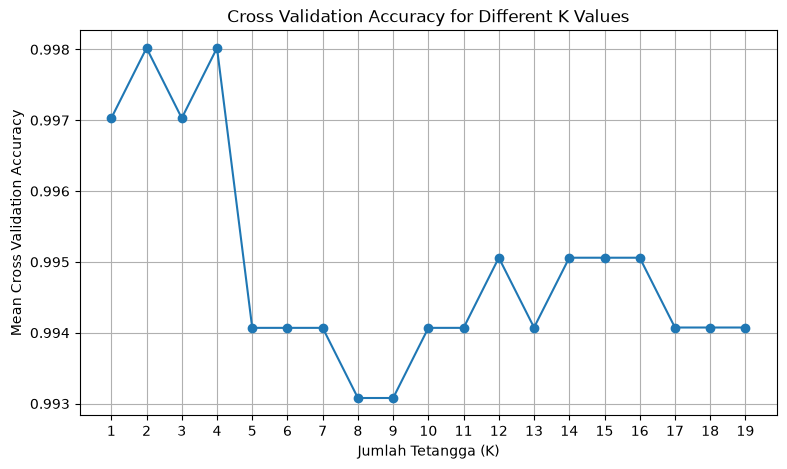

In [13]:
# Yoseva Faurensia Sitohang_202431195

hasil_grid = pd.DataFrame(grid_search.cv_results_)

nilai_k = hasil_grid['param_knn__n_neighbors'].astype(int)
skor_cv = hasil_grid['mean_test_score']

plt.figure(figsize=(9, 5))
plt.plot(nilai_k, skor_cv, marker='o', linestyle='-')

plt.title('Cross Validation Accuracy for Different K Values')
plt.xlabel('Jumlah Tetangga (K)')
plt.ylabel('Mean Cross Validation Accuracy')
plt.xticks(range(1, 20))
plt.grid(True)
plt.show()